In [1]:
import os 

import matplotlib.pyplot as plt
from collections import defaultdict
from datasets import load_dataset
from transformers import T5Tokenizer, T5ForConditionalGeneration

from configs import CHECKPOINT, DATASET, BATCH_SIZE
from metrics import compute_blue
from prediction import evaluate
from prefix_t5_model import PrefixT5
from translation_dataset import create_dataloader, TranslationDataset

In [40]:
t5_tokenizer = T5Tokenizer.from_pretrained(CHECKPOINT)
t5_model = T5ForConditionalGeneration.from_pretrained(CHECKPOINT)

## Data Preprocessing

In [41]:
# Load the dataset
dataset = load_dataset(DATASET, "en-fr")['train']

# Shuffle the dataset
shuffled_dataset = dataset.shuffle(seed=42)

# Split into train (80%), validation+test (20%)
train_valid_test = shuffled_dataset.train_test_split(test_size=0.2, seed=42)

# Split the validation+test into validation (10%) and test (10%)
valid_test = train_valid_test['test'].train_test_split(test_size=0.5, seed=42)

train_dataset = train_valid_test['train']
valid_dataset = valid_test['train']
test_dataset = valid_test['test']


In [4]:
test_dataset

Dataset({
    features: ['id', 'translation'],
    num_rows: 12709
})

In [5]:
train_translation_dataset = TranslationDataset(
    data=train_dataset,
    tokenizer=t5_tokenizer,
    shift_right_func=t5_model._shift_right
)

valid_translation_dataset = TranslationDataset(
    data=valid_dataset,
    tokenizer=t5_tokenizer,
    shift_right_func=t5_model._shift_right
)

test_translation_dataset = TranslationDataset(
    data=test_dataset,
    tokenizer=t5_tokenizer,
    shift_right_func=t5_model._shift_right
)

In [6]:
train_loader = create_dataloader(
    dataset=train_translation_dataset, 
    batch_size=BATCH_SIZE
)

valid_loader = create_dataloader(
    dataset=valid_translation_dataset, 
    batch_size=BATCH_SIZE
)

test_loader = create_dataloader(
    dataset=test_translation_dataset, 
    batch_size=BATCH_SIZE, 
)

In [7]:
print(f"Number of batches in train: {len(train_loader)}")
print(f"Number of batches in valid: {len(valid_loader)}")
print(f"Number of batches in test: {len(test_loader)}")

Number of batches in train: 6355
Number of batches in valid: 795
Number of batches in test: 795


In [8]:
# Get a sample batch
sample_batch = next(iter(train_loader))
    
print("\nSample batch shapes:")
for key, value in sample_batch.items():
    print(f"{key}: {value.shape}")

# Decode a sample from the batch
print("\n")
print("Input:", t5_tokenizer.decode(sample_batch['input_ids'][0].tolist(), skip_special_tokens=True))
print("Target:", t5_tokenizer.decode(sample_batch['labels'][0].tolist(), skip_special_tokens=True))


Sample batch shapes:
input_ids: torch.Size([16, 128])
attention_mask: torch.Size([16, 128])
labels: torch.Size([16, 128])
decoder_input_ids: torch.Size([16, 128])


Input: translate English to French: His heart beat so violently as he touched her doorthat he paused for breath.
Target: Son coeur battait si fort en touchant sa porte qu'il s'arrêtapour respirer.


## Prefix T5 Model

In [9]:
prefixed_t5_model = PrefixT5(
    t5_model=t5_model, prefix_length=10, prefix_projection_size=512
)

## Training

We implement the hyperparameter tuning for varied prefix length and learning rate by running the hyp_tuning_script.py. The results were saved for plotting and further analysis. 

## Evaluation

### Evaluate Prefix-T5 on test_dataset Using SacreBLEU

In [13]:
def prepend_trans_prefix(ds):
    examples = ds['translation']
    prefix = "translate English to French: "
    en_inputs = [prefix + example['en'] for example in examples]
    fr_targets = [example['fr'] for example in examples]
    return {'en': en_inputs, 'fr': fr_targets}

prefixed_test_dataset = test_dataset.map(prepend_trans_prefix, batched=True).remove_columns(["id", "translation"])

In [14]:
model_file_paths = [
    os.path.join("models", f)
    for f in os.listdir("models")
    if os.path.isfile(os.path.join("models", f))
]

bleu_scores = []

for model_path in model_file_paths:
    bleu_score = evaluate(
        model_path=model_path, 
        srcs=prefixed_test_dataset[0:10]['en'],
        refs=prefixed_test_dataset[0:10]['fr'],
        t5_model=t5_model, 
        t5_tokenizer=t5_tokenizer
    )
    bleu_scores.append(bleu_score)

Passing a tuple of `past_key_values` is deprecated and will be removed in Transformers v4.48.0. You should pass an instance of `EncoderDecoderCache` instead, e.g. `past_key_values=EncoderDecoderCache.from_legacy_cache(past_key_values)`.


Model successfully loaded from models/prefix_len_10-proj_size_512-lr_5e-05.pth
Model successfully loaded from models/prefix_len_15-proj_size_512-lr_8e-05.pth
Model successfully loaded from models/prefix_len_5-proj_size_512-lr_5e-05.pth
Model successfully loaded from models/prefix_len_5-proj_size_512-lr_8e-05.pth
Model successfully loaded from models/prefix_len_10-proj_size_512-lr_8e-05.pth
Model successfully loaded from models/prefix_len_15-proj_size_512-lr_5e-05.pth


In [45]:
bleu_scores = [
{'prefix_length': 10, 'learning_rate': '5e-05', 'blue': 12.36},
{'prefix_length': 15, 'learning_rate': '8e-05', 'blue': 12.36},
{'prefix_length': 5, 'learning_rate': '5e-05', 'blue': 13.41},
{'prefix_length': 5, 'learning_rate': '8e-05', 'blue': 10.89},
{'prefix_length': 10, 'learning_rate': '8e-05', 'blue': 10.80},
{'prefix_length': 15, 'learning_rate': '5e-05', 'blue': 12.26}
]

In [47]:
bleu_scores

[{'prefix_length': 10, 'learning_rate': '5e-05', 'blue': 12.36},
 {'prefix_length': 15, 'learning_rate': '8e-05', 'blue': 12.36},
 {'prefix_length': 5, 'learning_rate': '5e-05', 'blue': 13.41},
 {'prefix_length': 5, 'learning_rate': '8e-05', 'blue': 10.89},
 {'prefix_length': 10, 'learning_rate': '8e-05', 'blue': 10.8},
 {'prefix_length': 15, 'learning_rate': '5e-05', 'blue': 12.26}]

In [48]:
def plot_dual_axis(data, x_key, y_key, category_key, x_label, y_labels, colors, markers):
    grouped_data = defaultdict(list)
    for entry in data:
        grouped_data[entry[category_key]].append((entry[x_key], entry[y_key]))

    categories = list(grouped_data.keys())
    group_1 = sorted(grouped_data[categories[0]], key=lambda x: x[0])  # Sort by x_key
    group_2 = sorted(grouped_data[categories[1]], key=lambda x: x[0])

    x_1, y_1 = zip(*group_1)
    x_2, y_2 = zip(*group_2)

    fig, ax1 = plt.subplots()

    ax1.plot(x_1, y_1, marker=markers[0], color=colors[0], label=f"{y_labels[0]}")
    ax1.set_xlabel(x_label)
    ax1.set_ylabel(y_labels[0], color=colors[0])
    ax1.tick_params(axis='y', labelcolor=colors[0])
    ax1.legend(loc='center left')

    ax2 = ax1.twinx()
    ax2.plot(x_2, y_2, marker=markers[1], color=colors[1], label=f"{y_labels[1]}")
    ax2.set_ylabel(y_labels[1], color=colors[1])
    ax2.tick_params(axis='y', labelcolor=colors[1])
    ax2.legend(loc='center right')

    fig.tight_layout()
    plt.show()

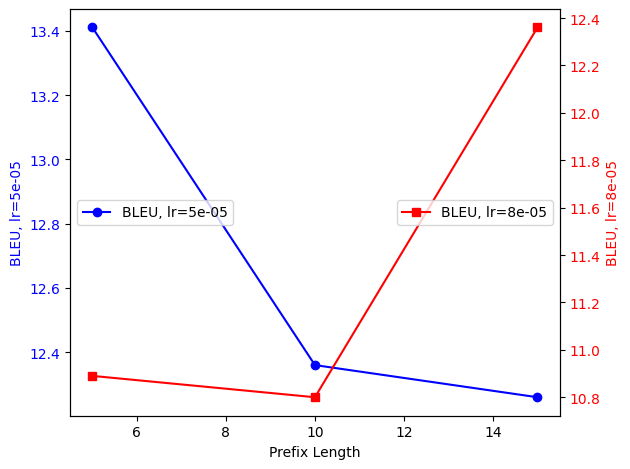

In [49]:
plot_dual_axis(
    data=bleu_scores,
    x_key="prefix_length",
    y_key="blue",
    category_key="learning_rate",
    x_label="Prefix Length",
    y_labels=["BLEU, lr=5e-05", "BLEU, lr=8e-05"],
    colors=["blue", "red"],
    markers=["o", "s"]
)

### Evaluate base T5 model on test_dataset Using SacreBLEU

In [42]:
test_loader = create_dataloader(
    dataset=test_translation_dataset, 
    batch_size=10, 
)

In [ ]:
preds = []
refs = []

for batch in test_loader:    
    input_ids = batch["input_ids"]
    attention_mask = batch["attention_mask"]
    labels = batch["labels"]

    outputs = t5_model.generate(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
    labels[labels == -100] = t5_tokenizer.pad_token_id

    for i in range(len(outputs)):
        pred = t5_tokenizer.decode(outputs[i], skip_special_tokens=True)
        ref = t5_tokenizer.decode(labels[i], skip_special_tokens=True)
        preds.append(pred)
        refs.append(ref)
    
    break

base_t5_bleu_score = compute_blue(refs, preds)

In [52]:
base_t5_bleu_score

15.17